# Once both runs have learned their answers, does the carrying set separate a wrong-answer fine-tune from a true-answer one? (E109)

*2026-11-06. Provisional, fast lane. Full record: `reports/analyses/2026-11-06_analysis_e109-neurons-larger-size.md`.
Jobs 54053 and 54062, one L40 on the cluster's debug queue, $0.*

## The answer

Both fine-tunes learned their answers: the wrong-answer run prefers the wrong sentence in essentially every row. But
at this size the carrying set is not reproducible enough to read anything. Two runs on the same data, differing only in
shuffling order, share about two thirds of their top neurons, against nine tenths early in training. That spread is
wider than the gap to an unrelated fictional-author run, so the filed test had no power on either probe and makes no
call.


## What we were trying to test

`GOALS.md` asks whether post-training strengthens what a model already does or teaches it something new, and whether
any reading can tell the two apart. This line reads one non-decomposition instrument: which neurons carry a weight
update.

**The two runs.** The *true-answer run* fine-tunes Qwen3-1.7B on TOFU's 217 real-person and world-fact questions, each
answered in a sentence stating the true answer, which the unchanged model already gives. The *wrong-answer run* uses
the same questions, wordings and writer, with each true answer swapped for TOFU's first wrong one: "The author of
'Romeo and Juliet' is Charles Dickens." Only whether the stated fact agrees with what the model already says differs.
Each run has two data-order seeds, 42 and 142, and runs the full five-epoch recipe to step 335. There the total weight
change has a size of about 8.3, against about 0.49 at the *matched size* E107 read early in training. The
*fictional-author run*, trained on TOFU's invented authors, is the reference for an unrelated update, read at its first
learned state.

**What is read.** The *carrying set* of a run on a probe is the 1,024 MLP neurons, out of 172,032, with the largest
first-order share of the update's gain: the unchanged model's gradient of the answer log-probability times the change
in each neuron's firing. The *overlap* of two sets is the share of the first inside the second: 1 is the same set, two
random sets share about 0.006. Two probes are scored. The *TOFU rows* are 128 rows of fictional-author text that neither
run trained on, read over the whole answer. The *answer tokens* probe reads the 217 true sentences only where the model
predicts a token of the true answer, ranking neurons by the size of their score whatever its sign.

**The comparison.** The *seed level* is how much a run's set agrees with itself under a new shuffling seed. The
*cross-arm overlap* is the wrong run's set inside the true run's. The *fictional reference*, called x, is the highest
overlap of the true run's set with the fictional run's. If the label moved the set, the cross-arm overlap would fall
from the seed level toward x. That is readable only if the seed level stands clear of x by more than the seed noise,
one minus the seed level: the filed *power gate*. In the figure the gate is a dashed line at one plus x, halved.

**Controls, run first.** Stored states and the unchanged model's levels were re-read to their stored numbers, and the
true-answer end states had to prefer the wrong sentence no more often than the unchanged model. The *learned gate*
asked each wrong-answer end state to prefer the wrong sentence in at least three quarters of rows.


## What we expected, and why

- **The wrong run would learn its answers**, preferring the wrong sentence in 90 to 100 percent of rows: five epochs of
  this recipe teach the fictional run its facts.
- **Power on both probes** was the lean. A dry run's stand-in on the TOFU rows read a seed level of 0.83 against an x of
  0.42, well clear of the line.
- **The label reading.** On the TOFU rows the lean was "topic or style", the wrong run's set staying with the true
  run's, since the shared sentence frame dominates a whole-row read. On the answer tokens the lean was "familiarity",
  the set moving toward the fictional run, with "no call" thought likelier.


In [1]:
from pathlib import Path

from IPython.display import Image, display

from commute.jobs import load_experiment

PLOT = load_experiment("larger_size", "plot")
PLOT.FIG.mkdir(exist_ok=True)
PLOT.plot_seeds(PLOT.panels())  # redraws both figures from results/*.json and stored sets; no model
PLOT.plot_learned()
FIG = Path("../experiments/larger_size/figures")


## What we observed

### Has each run learned the answers it was trained on?


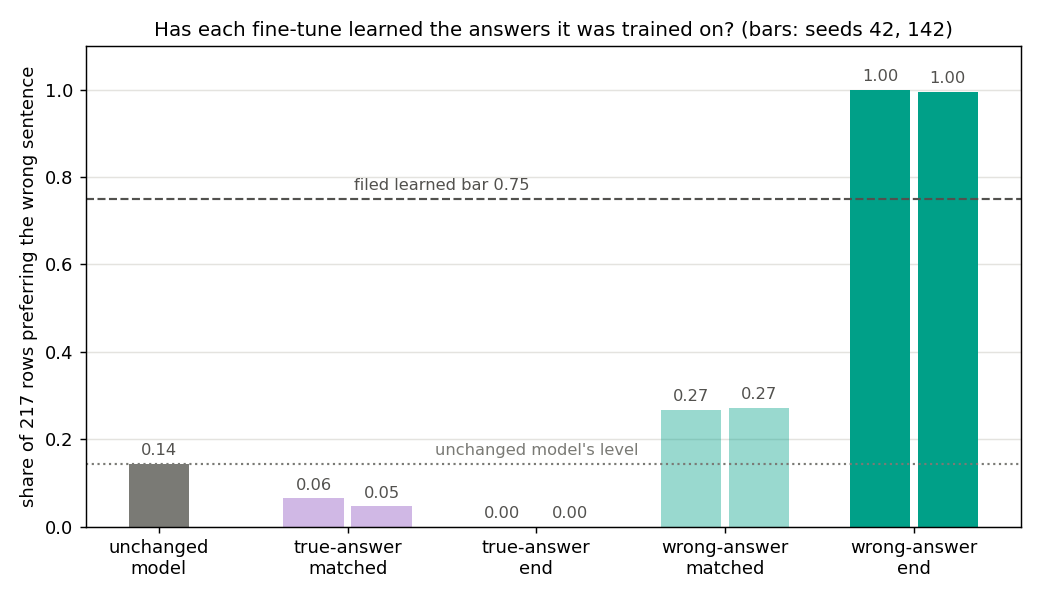

In [2]:
display(Image(FIG / "learned.png", width=750))


**Reading it.** Yes. Both wrong-answer end states prefer the wrong sentence in all or all but one of the 217 rows, far
over the filed bar of three quarters. Their greedy answers recall 98 to 99 percent of the wrong answer's words. Both
true-answer end states prefer the wrong sentence in no row, under the unchanged model's 14 percent, so the control held.
At the matched size the wrong run preferred the wrong sentence in only 27 percent of rows, while the true run sat at 5
to 6 percent. That settles a question E107 left open: the early rise is specific to training wrong answers. The facts
the comparison needs are learned at this size.

### Is the carrying set stable enough across seeds to read the label?


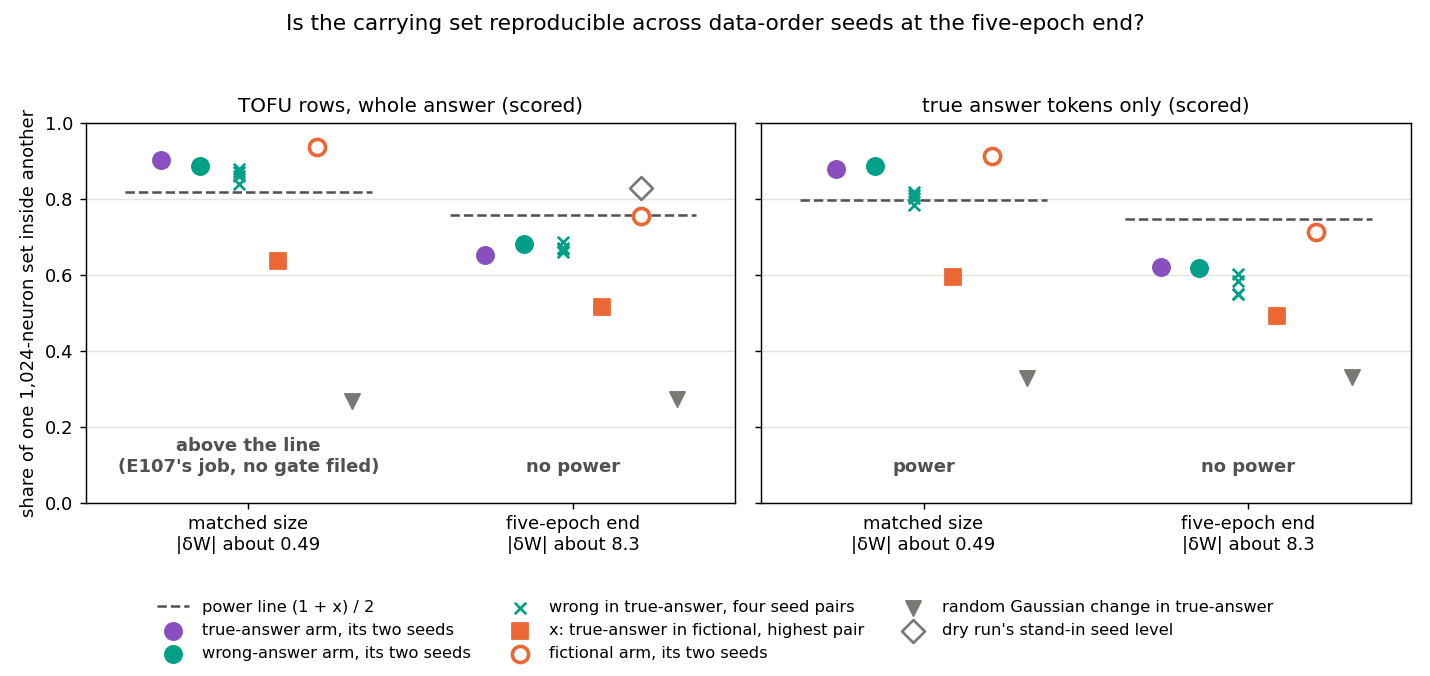

In [3]:
display(Image(FIG / "seeds.png", width=950))


**Reading it.** No, on either probe. At the five-epoch end the true run's two seeds share 0.65 of their set on the TOFU
rows and 0.62 on the answer tokens, both under the dashed power line near 0.75. At the matched size the same quantities
were 0.90 and 0.88, above their lines. The wrong run's seeds fall the same way, so the instability is not one run's. A
random Gaussian weight change, grey triangles, picks a set sharing about 0.3 with the true run's: part of every set is
fixed by where the unchanged model's gradient is large. Between that floor and the seed level there is now about 0.3 of
room, less than the seed noise the rule must clear. The wrong run's set sits inside the true run's at 0.66 to 0.69 on
the TOFU rows, level with both seed levels. With no power that is not a reading of the label in either direction.

**Why the dry run expected power.** It had no second seed of the true run's end state on the TOFU rows. So its stand-in
took the seed level from the fictional run's seeds at the end of its grid, the grey diamond at 0.83. The fictional run
is the more reproducible on both probes, orange rings. On the TOFU rows its gain is about twice the true run's, so its
set rests on more signal. That does not explain the answer tokens, where the fictional gain is near zero and its seeds
still agree more. Why the true run's set moves so much with the seed is not run down.


## What we learned

At the five-epoch end of this recipe the top-1,024 carrying set of a Qwen3-1.7B fine-tune is far less reproducible
across data-order seeds than early in training, on every probe read. The seed noise is now wider than the distance to
an unrelated update, so the set cannot read whether an update confirms or contradicts what the model knew, though the
facts are learned. Early in training the set was stable, but the wrong run had not learned its facts. So no size read
so far has both a learned label and a stable set, and the neuron baseline gives no known-against-new reading for this
pair. E107's early "topic or style" stands as a size control only.

## How compelling is the evidence

- **Blind to** rank inside a set, neurons just past the cut, sign on the answer tokens, and anything inside a neuron.
  A contradicted fact is not a new entity. The fictional reference is at a weight change near 15, not 8.3.
- **Two seeds per run.** Both runs fell to the same place, which makes one unlucky seed unlikely, but the spread of
  the seed level itself is unmeasured.
- **The first-order score may not track the update at this size.** In four reads the summed first-order score is
  positive while the measured gain is negative: both wrong ends on the answer tokens and on the real rows, and one true
  end on the real rows. Not tested.
- **The verdict is the filed one.** No rule was re-scored, added or loosened.

## Surprises

- **The power lean failed on both scored probes**: seed levels 0.65 and 0.62 against a line near 0.75. This is a miss
  about the instrument, not a reversed finding about the model.
- **The true run's seeds disagree on the real rows**, a reported probe: seed 42 raises its own true facts by 0.80 nats a
  token, seed 142 lowers them by 2.34. Not run down.
- **Narrow misses of reported reads**: the sentence gaps were smaller than filed, and the size-ranked set lies 0.66
  inside the signed one against at least 0.8 expected.

## What next

No amendment is opened: a "no call" is reported as read. What one could test, not filed:

1. **A set size or ranking whose seed level holds at this size**, for example several set sizes, or the gradient taken
   at the fine-tuned state. Minutes on a debug card for the saved states. If none holds, the neuron baseline is closed
   for this pair at the learned size.
2. **More seeds**, to measure the seed level's own spread. If a third seed agrees at 0.9 with one of the two, one seed
   is the outlier.
3. **Genuinely new facts in the known style**, ask 23's option (b), which would need item 1 first.


## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| stage 0 | apparatus reproduces stored numbers; true end prefers wrong no more than the unchanged model | exact or within 3e-8; 0.000, 0.000 | holds |
| learned | each wrong seed prefers wrong ≥ 0.75 and recalls ≥ 0.585 | 1.000 / 0.984; 0.995 / 0.991 | holds |
| power, TOFU rows | w − x > 1 − w | 0.139 against 0.348 | no power; lean power |
| power, answer tokens | same | 0.129 against 0.380 | no power; lean power |
| rule, TOFU rows | familiarity, topic or style, or no call | cross 0.658 to 0.687 | no call, no power at this size |
| rule, answer tokens | same | cross 0.548 to 0.601 | no call, no power at this size |

## Reads under, and departures

Not a reuse verdict, so `decisions.md` rows 81 and 87 do not apply. It reads under line 152, the matched step as a size
control only, and line 160, ask 23 option (a). Departures from the literature: TOFU's wrong answers are evaluation
distractors in Maini et al. 2024, used here as training targets; TOFU's real-person sets are evaluation sets there,
training rows here. The carrying-set ranking is E98's, and the overlap rules and gates are this project's.

## Not run

- A fictional run at a weight change of 8.3; the true and wrong runs trained on to 15.5.
- Any other set size, a ranking by the gradient at the fine-tuned state, or more than two seeds per run.
- Per-neuron scores were not saved, so a new set size needs a GPU re-read.
- The real-row seed disagreement was not run down.
- Genuinely new facts in the known style; VPD reads of the wrong end states, handed to qwen-decomp-lead.

**Provenance.** Jobs 54053 and 54062 on one debug L40, 327 s and 767 s, $0; job 54042 crashed after its control passed
and was fixed in 109b99ab. Results `experiments/larger_size/results/`, committed at 58ff835b. Figures from
`experiments/larger_size/plot.py`.
